In [1]:
import sys
sys.path.insert(0, "..")

import time
from src.features import build_feature_table
from src.config import CACHE

start = time.time()
features_raw = build_feature_table(derivative=False)       # same pipeline, raw recordings
print(features_raw.shape, "| minutes:", round((time.time() - start) / 60, 1))

# sanity check: all feature columns should have values for every row
print("missing values:", features_raw.isna().sum().sum())

features_raw.to_pickle(CACHE / "features_raw_4s.pkl")

(17604, 116) | minutes: 1.2
missing values: 0


## Preprocessing comparison
Same features and models, four settings: the cleaned recordings (ICA + artifact removal, from `derivatives/`) vs the raw ones, and three epoch lengths.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from src.features import load_spectra, feature_table
from src.models import make_logreg, make_rf
from src.evaluate import repeat_cv
from src.config import RESULTS

# each setting: (use the cleaned recordings?, epoch length in seconds)
settings = {"cleaned 4s": (True, 4.0), "raw 4s": (False, 4.0),
            "cleaned 2s": (True, 2.0), "cleaned 8s": (True, 8.0)}
models = {"LogReg": make_logreg, "RandomForest": make_rf}
tasks = [["AD", "CN"], ["AD", "FTD", "CN"]]

rows = []
for setting, (derivative, duration) in settings.items():
    feats = feature_table(load_spectra(derivative, duration))     # spectra are cached after the first run
    for classes in tasks:
        for model_name, make_model in models.items():
            row = repeat_cv(feats, make_model, classes, n_seeds=3)  # 3 shuffles, to keep it quick
            row.update({"setting": setting, "task": "-".join(classes), "model": model_name})
            rows.append(row)

comparison = pd.DataFrame(rows).round(3)
print(comparison[["setting", "task", "model", "accuracy", "macro_f1"]].to_string(index=False))
comparison.to_csv(RESULTS / "preprocessing_comparison.csv", index=False)

   setting      task        model  accuracy  macro_f1
cleaned 4s     AD-CN       LogReg     0.790     0.788
cleaned 4s     AD-CN RandomForest     0.821     0.820
cleaned 4s AD-FTD-CN       LogReg     0.580     0.552
cleaned 4s AD-FTD-CN RandomForest     0.648     0.591
    raw 4s     AD-CN       LogReg     0.800     0.799
    raw 4s     AD-CN RandomForest     0.810     0.808
    raw 4s AD-FTD-CN       LogReg     0.572     0.532
    raw 4s AD-FTD-CN RandomForest     0.686     0.636
cleaned 2s     AD-CN       LogReg     0.785     0.784
cleaned 2s     AD-CN RandomForest     0.800     0.798
cleaned 2s AD-FTD-CN       LogReg     0.610     0.578
cleaned 2s AD-FTD-CN RandomForest     0.617     0.552
cleaned 8s     AD-CN       LogReg     0.841     0.840
cleaned 8s     AD-CN RandomForest     0.815     0.815
cleaned 8s AD-FTD-CN       LogReg     0.553     0.517
cleaned 8s AD-FTD-CN RandomForest     0.640     0.596


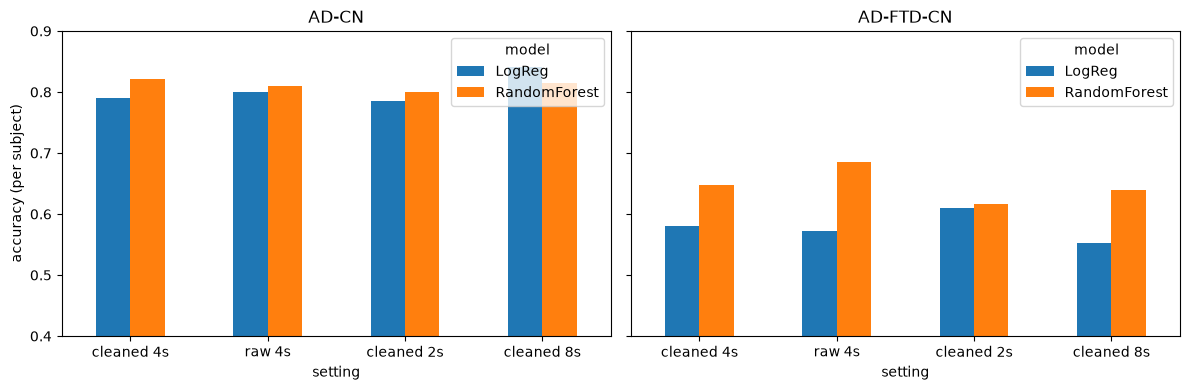

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, task in zip(axes, comparison.task.unique()):
    part = comparison[comparison.task == task].pivot(index="setting", columns="model", values="accuracy")
    part.loc[list(settings)].plot.bar(ax=ax, rot=0)
    ax.set_title(task)
    ax.set_ylabel("accuracy (per subject)")
    ax.set_ylim(0.4, 0.9)
plt.tight_layout()
plt.savefig(RESULTS / "preprocessing_comparison.png", dpi=120)
plt.show()